# ShapeSplatsV1 chairs — dataset look

Uses `splat_utils.py`, which sits next to this notebook. No install, no
config file — just edit `DATA_DIR` below and run.

In [3]:
%matplotlib inline
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from splat_utils import read_splat, find_ply_files, object_stats, render_points

DATA_DIR = "/lustre/data/mls04/ShapeSplatsV1/extracted/03001627_0"
UP_AXIS = 2   # 0=x, 1=y, 2=z

files = find_ply_files(DATA_DIR)
print(f"{len(files)} .ply files under {DATA_DIR}")

0 .ply files under /lustre/data/mls04/ShapeSplatsV1/extracted/03001627_0


## 1. Look at one file

`read_splat` returns a plain dict of numpy arrays with the activations
already applied (sigmoid on opacity, exp on scale, normalised quaternion).

In [4]:
s = read_splat(files[0])
print(f"{s['name']}: {s['n']:,} gaussians")
for k in ["xyz", "scale", "quat", "opacity", "rgb"]:
    v = s[k]
    print(f"  {k:<10} shape={v.shape}  min={v.min():.4f}  max={v.max():.4f}")

IndexError: list index out of range

In [5]:
# quick sanity check: raw stored values vs activated
print(f"raw log-scale   min {s['log_scale'].min():.3f}  max {s['log_scale'].max():.3f}")
print(f"activated scale min {s['scale'].min():.5f}  max {s['scale'].max():.5f}")
print(f"raw opacity     min {s['opacity_logit'].min():.3f}  max {s['opacity_logit'].max():.3f}")
print(f"activated       min {s['opacity'].min():.3f}  max {s['opacity'].max():.3f}")

NameError: name 's' is not defined

## 2. A quick render

In [6]:
img = render_points(s, azim=35, elev=18, up_axis=UP_AXIS)
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"{s['name']} -- {s['n']:,} gaussians")
plt.axis("off")
plt.show()

NameError: name 's' is not defined

## 3. Which axis is up?

Render all three and look. Set `UP_AXIS` in the first cell once you know.

NameError: name 's' is not defined

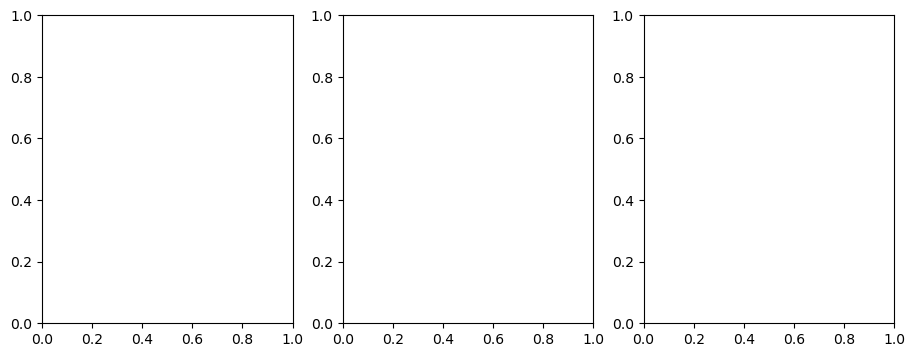

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, axis in zip(axes, (0, 1, 2)):
    ax.imshow(render_points(s, azim=40, elev=15, up_axis=axis))
    ax.set_title(f"up_axis={axis} ({'xyz'[axis]}-up)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Stats over the whole category

In [8]:
t0 = time.time()
rows = [object_stats(read_splat(f)) for f in files]
df = pd.DataFrame(rows)
print(f"{len(df)} objects in {time.time() - t0:.0f}s")
df.head()

0 objects in 0s


""


In [9]:
df.to_csv("object_stats.csv", index=False)
df.describe()

ValueError: Cannot describe a DataFrame without columns

## 5. How many Gaussians per object?

In [ ]:
n = df["n_gaussians"].values
plt.figure(figsize=(6, 3.5))
plt.hist(n, bins=50, color="#4C72B0")
plt.axvline(32768, color="crimson", ls="--", label="32768 = 32³")
plt.xlabel("gaussians per object"); plt.ylabel("objects"); plt.legend()
plt.show()

print(f"median {np.median(n):,.0f}   range [{n.min():,} .. {n.max():,}]")

## 6. Geometry, scale, opacity, rotation

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

axes[0,0].hist(df["radius"], bins=50, color="#55A868")
axes[0,0].set(xlabel="object radius", title="object size")

axes[0,1].hist(df["log_scale_mean"], bins=50, color="#8172B2")
axes[0,1].set(xlabel="mean log(scale)", title="gaussian scale")

axes[1,0].hist(df["opacity_mean"], bins=50, color="#C44E52")
axes[1,0].set(xlabel="mean opacity", title="opacity")

axes[1,1].hist(df["frac_quat_w_negative"], bins=40, color="#DD8452")
axes[1,1].axvline(0.5, color="k", ls="--")
axes[1,1].set(xlabel="fraction with quat w < 0", title="0.5 = not canonicalised")

plt.tight_layout()
plt.show()

## 7. A grid of random chairs

In [ ]:
rng = np.random.default_rng(0)
picks = sorted(rng.choice(len(files), min(12, len(files)), replace=False))

fig, axes = plt.subplots(3, 4, figsize=(13, 10))
for ax, i in zip(axes.ravel(), picks):
    obj = read_splat(files[i])
    ax.imshow(render_points(obj, azim=40, elev=15, up_axis=UP_AXIS))
    ax.set_title(f"{obj['name']} ({obj['n']//1000}k)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

---

Things worth noting from that grid: consistent scale/orientation across
objects, and any obviously broken reconstructions to filter before training.